In [1]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080304

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp01_env
[学号]       20244080304
[机器指纹] 5fc15abbc5865ff7
[RUN_ID]   20244080304-5fc15abbc5865ff7


# 作业3：NumPy、Matplotlib 与 pandas

学号：20244080304　姓名：李晓月

## 一、半圆定律

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(202440803)

In [3]:
def wigner_density(x):
    if -2 <= x <= 2:
        return float(np.sqrt(4 - x**2) / (2 * np.pi))
    return 0.0


for x in [-2, -1, 0, 1, 2, 3]:
    print(x, wigner_density(x))

-2 0.0
-1 0.27566444771089604
0 0.3183098861837907
1 0.27566444771089604
2 0.0
3 0.0


In [4]:
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    upper = np.triu(np.random.normal(0, np.sqrt(1 / n), size=(n, n)))
    return upper + np.triu(upper, 1).T


matrix = generate_wigner(5)
print(matrix.shape)
print(np.allclose(matrix, matrix.T))

(5, 5)
True


In [5]:
def get_spectrum(matrix):
    return np.sort(np.linalg.eigvalsh(matrix))


print(get_spectrum(generate_wigner(5)))

[-1.38410435 -0.69597649  0.10080528  0.42023502  1.98489024]


In [6]:
sizes = [100, 200, 500, 1000]
spectra = {n: get_spectrum(generate_wigner(n)) for n in sizes}

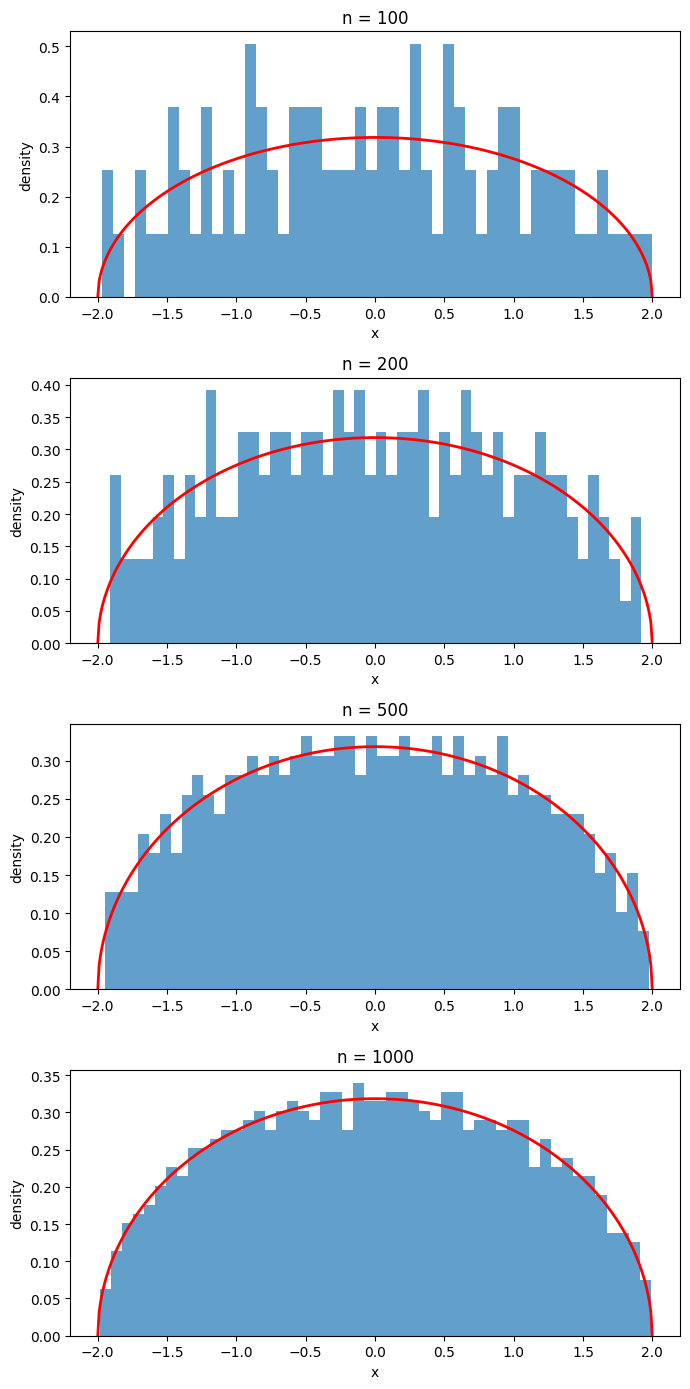

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(7, 14))
x = np.linspace(-2, 2, 400)
y = np.array([wigner_density(v) for v in x])

for ax, n in zip(axes, sizes):
    ax.hist(spectra[n], bins=50, density=True, color="tab:blue", alpha=0.7)
    ax.plot(x, y, color="red", linewidth=2)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("x")
    ax.set_ylabel("density")

fig.tight_layout()
plt.show()

从图中看，n=100 时已经呈现中间高、两侧低的半圆轮廓；n=500 和 n=1000 时，直方图与红色半圆密度曲线基本重合。因此 n 大约达到 500 时，半圆密度能较好地拟合特征值分布。

## 二、Conway 生命游戏

In [8]:
def is_valid_board(board):
    return bool(
        isinstance(board, np.ndarray)
        and board.ndim == 2
        and np.isin(board, [0, 1]).all()
    )


print(is_valid_board(np.array([[0, 1], [1, 0]])))
print(is_valid_board(np.array([0, 1, 0])))
print(is_valid_board(np.array([[0, 1], [1, 2]])))

True
False
False


In [9]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效的棋盘")

    neighbors = sum(
        np.roll(np.roll(board, i, axis=0), j, axis=1)
        for i in (-1, 0, 1)
        for j in (-1, 0, 1)
        if (i, j) != (0, 0)
    )
    alive = board == 1
    return ((alive & ((neighbors == 2) | (neighbors == 3)))
            | (~alive & (neighbors == 3))).astype(int)


blinker = np.zeros((5, 5), dtype=int)
blinker[2, 1:4] = 1
print(gol_step(blinker))
print(np.array_equal(gol_step(gol_step(blinker)), blinker))

[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]
True


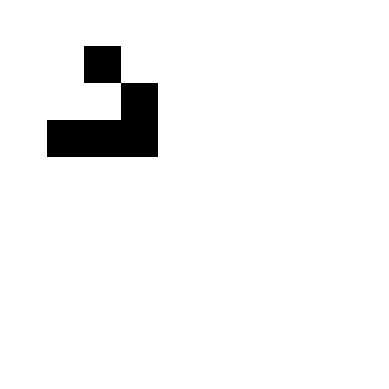

In [10]:
def draw_gol_board(board):
    plt.imshow(board, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()


glider = np.zeros((10, 10), dtype=int)
glider[1, 2] = 1
glider[2, 3] = 1
glider[3, 1:4] = 1
draw_gol_board(glider)

## 三、使用 pandas DataFrame

In [11]:
df = pd.read_csv("Iris.csv")

print("数据点个数：", len(df))
print("列名：", list(df.columns))
print("各列数据类型：")
print(df.dtypes)
print("花卉种类数：", df["Species"].nunique())
print(df["Species"].value_counts())
df.head()

数据点个数： 150
列名： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
各列数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object
花卉种类数： 3
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


数据集有 150 个数据点；`Id` 为整数，四个测量列均为 `float64`，`Species` 为字符串；共有 3 种花卉，每种 50 条。

In [12]:
columns = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]

print("修正前：")
print(df.loc[[34, 37]])

df.loc[34, columns] = [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
df.loc[37, columns] = [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

print("修正后：")
print(df.loc[[34, 37]])

修正前：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.1  Iris-setosa
37  38            4.9           3.1            1.5           0.1  Iris-setosa
修正后：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa


In [13]:
df["Petal.Ratio"] = (df["PetalLengthCm"] / df["PetalWidthCm"]).round(6)
df["Sepal.Ratio"] = (df["SepalLengthCm"] / df["SepalWidthCm"]).round(6)

df.loc[[34, 37]]

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
34,35,4.9,3.1,1.5,0.2,Iris-setosa,7.5,1.580645
37,38,4.9,3.6,1.4,0.1,Iris-setosa,14.0,1.361111


In [14]:
df.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv")
print(df.shape)
print(df.columns.tolist())

已保存 iris_corrected.csv
(150, 8)
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species', 'Petal.Ratio', 'Sepal.Ratio']


In [15]:
summary = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
summary.round(4)

Petal.Ratio                               Sepal.Ratio          \
                       mean  median     min   max     std        mean  median   
Species                                                                         
Iris-setosa          6.9080  7.0000  2.6667  15.0  2.8545      1.4702  1.4631   
Iris-versicolor      3.2428  3.2404  2.6667   4.1  0.3125      2.1604  2.1613   
Iris-virginica       2.7807  2.6667  2.1250   4.0  0.4074      2.2305  2.1695   

                                         
                    min     max     std  
Species                                  
Iris-setosa      1.2683  1.9565  0.1187  
Iris-versicolor  1.7647  2.8182  0.2287  
Iris-virginica   1.8235  2.9615  0.2470